In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, RandomizedSearchCV,
                                     cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, precision_recall_curve)

SEED = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
BLUE, GREY, RED = '#3B7FC0', '#A9B4BA', '#C62828'

## 1. Load the customer churn dataset


In [2]:
CSV = 'Telco-Customer-Churn.csv'
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(CSV if os.path.exists(CSV) else URL)

print(f"Shape: {df.shape[0]} customers x {df.shape[1]} columns")
df.head()

Shape: 7043 customers x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.dtypes.value_counts(), "\n")
print("Missing values per column (as loaded):", int(df.isna().sum().sum()))
print("\nChurn distribution:")
print(df['Churn'].value_counts().to_string())
print(f"\nChurn rate = {(df['Churn'] == 'Yes').mean():.2%}  -> the classes are imbalanced (about 1 in 4 customers churn)")

str        18
int64       2
float64     1
Name: count, dtype: int64 

Missing values per column (as loaded): 0

Churn distribution:
Churn
No     5174
Yes    1869

Churn rate = 26.54%  -> the classes are imbalanced (about 1 in 4 customers churn)


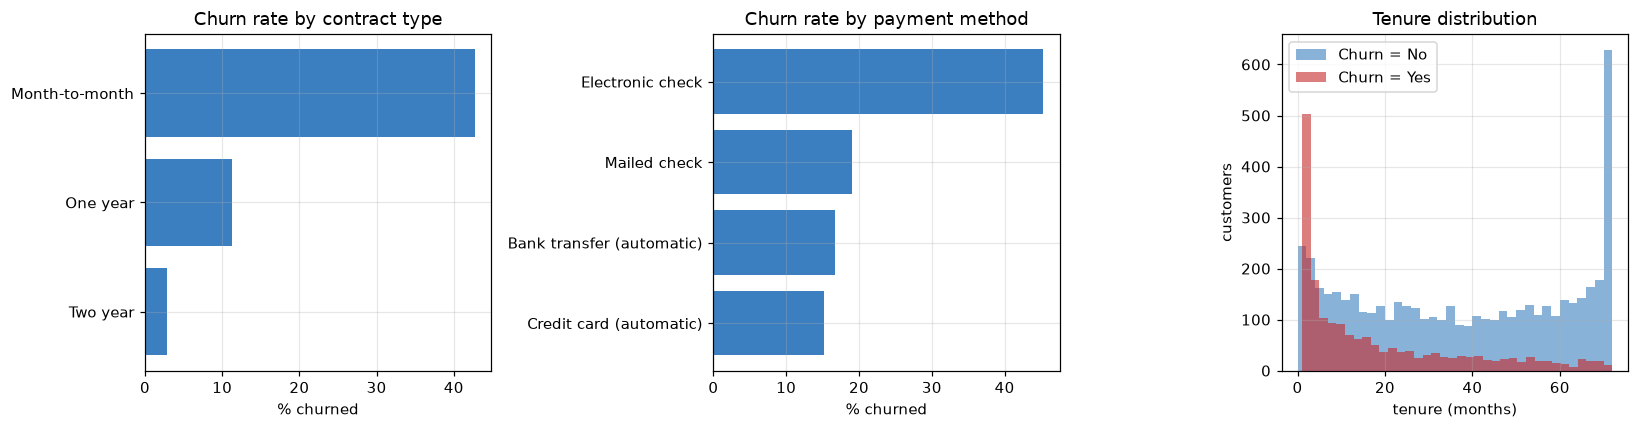

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
rate = lambda col: df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()

r = rate('Contract'); ax[0].barh(r.index, r.values, color=BLUE)
ax[0].set(title='Churn rate by contract type', xlabel='% churned')
r = rate('PaymentMethod'); ax[1].barh(r.index, r.values, color=BLUE)
ax[1].set(title='Churn rate by payment method', xlabel='% churned')
for lab, col in (('No', BLUE), ('Yes', RED)):
    ax[2].hist(df.loc[df['Churn'] == lab, 'tenure'], bins=36, alpha=0.6, color=col, label=f'Churn = {lab}')
ax[2].set(title='Tenure distribution', xlabel='tenure (months)', ylabel='customers'); ax[2].legend()
plt.tight_layout(); plt.show()



## 2. Feature encoding and data preprocessing

In [5]:
data = df.copy()

# 1. types
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print("Blank TotalCharges:", data['TotalCharges'].isna().sum(),
      "| their tenure values:", data.loc[data['TotalCharges'].isna(), 'tenure'].unique())
data['TotalCharges'] = data['TotalCharges'].fillna(0.0)

# 2-3. identifier and target
customer_ids = data.pop('customerID')
y = (data.pop('Churn') == 'Yes').astype(int)

# 4. collapse redundant categories
data = data.replace({'No internet service': 'No', 'No phone service': 'No'})

# 5. feature engineering
ADDONS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
data['num_addon_services'] = (data[ADDONS] == 'Yes').sum(axis=1)
data['avg_monthly_spend'] = np.where(data['tenure'] > 0, data['TotalCharges'] / data['tenure'], data['MonthlyCharges'])
data['tenure_group'] = pd.cut(data['tenure'], bins=[-1, 12, 24, 48, 72],
                              labels=['0-12 m', '13-24 m', '25-48 m', '49-72 m']).astype(str)

# 6a. binary columns -> 0/1
BINARY = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling'] + ADDONS
data[BINARY] = (data[BINARY] == 'Yes').astype(int)
data['gender'] = (data['gender'] == 'Female').astype(int)
data = data.rename(columns={'gender': 'is_female'})

CATEGORICAL = ['InternetService', 'Contract', 'PaymentMethod', 'tenure_group']
NUMERIC = [c for c in data.columns if c not in CATEGORICAL]
print(f"\n{len(NUMERIC)} numeric / binary features:", NUMERIC)
print(f"{len(CATEGORICAL)} categorical features (one-hot):", CATEGORICAL)

# 7. stratified split
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    data, y, customer_ids, test_size=0.20, stratify=y, random_state=SEED)
print(f"\nTrain: {len(X_train)} customers (churn {y_train.mean():.2%}) | "
      f"Test: {len(X_test)} customers (churn {y_test.mean():.2%})")

preprocess = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
    ('num', 'passthrough', NUMERIC),
], verbose_feature_names_out=False)

X_enc = preprocess.fit(X_train).transform(X_train.head())
FEATURE_NAMES = list(preprocess.get_feature_names_out())
print(f"\nAfter encoding: {len(FEATURE_NAMES)} model features")
pd.DataFrame(X_enc, columns=FEATURE_NAMES).iloc[:, :12]

Blank TotalCharges: 11 | their tenure values: [0]

18 numeric / binary features: ['is_female', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'num_addon_services', 'avg_monthly_spend']
4 categorical features (one-hot): ['InternetService', 'Contract', 'PaymentMethod', 'tenure_group']

Train: 5634 customers (churn 26.54%) | Test: 1409 customers (churn 26.54%)

After encoding: 32 model features


,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12 m,tenure_group_13-24 m
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 3. Gradient Boosting classifier

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

gb_default = Pipeline([('prep', preprocess), ('gb', GradientBoostingClassifier(random_state=SEED))])
gb_default.fit(X_train, y_train)

param_dist = {
    'gb__n_estimators': [100, 200, 300, 400],
    'gb__learning_rate': [0.02, 0.05, 0.1],
    'gb__max_depth': [2, 3, 4],
    'gb__subsample': [0.7, 0.85, 1.0],
    'gb__min_samples_leaf': [1, 10, 30],
}
search = RandomizedSearchCV(
    Pipeline([('prep', preprocess), ('gb', GradientBoostingClassifier(random_state=SEED))]),
    param_dist, n_iter=20, scoring='roc_auc', cv=cv, n_jobs=-1, random_state=SEED)
search.fit(X_train, y_train)
gb = search.best_estimator_

print("Best hyperparameters:")
for k, v in search.best_params_.items(): print(f"  {k.replace('gb__', ''):<18} {v}")
print(f"\nCross-validated ROC-AUC: tuned = {search.best_score_:.4f}")

top = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(5)
top[['param_gb__n_estimators', 'param_gb__learning_rate', 'param_gb__max_depth', 'param_gb__subsample',
     'param_gb__min_samples_leaf', 'mean_test_score', 'std_test_score']].rename(columns=lambda c: c.replace('param_gb__', ''))

Best hyperparameters:
  subsample          0.85
  n_estimators       200
  min_samples_leaf   10
  max_depth          2
  learning_rate      0.05

Cross-validated ROC-AUC: tuned = 0.8494


,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf,mean_test_score,std_test_score
13,200,0.05,2,0.85,10,0.849,0.011
4,100,0.05,4,0.70,1,0.849,0.011
17,300,0.05,2,1.00,1,0.849,0.011
9,100,0.05,3,0.70,1,0.849,0.011
3,400,0.02,2,0.70,1,0.849,0.012


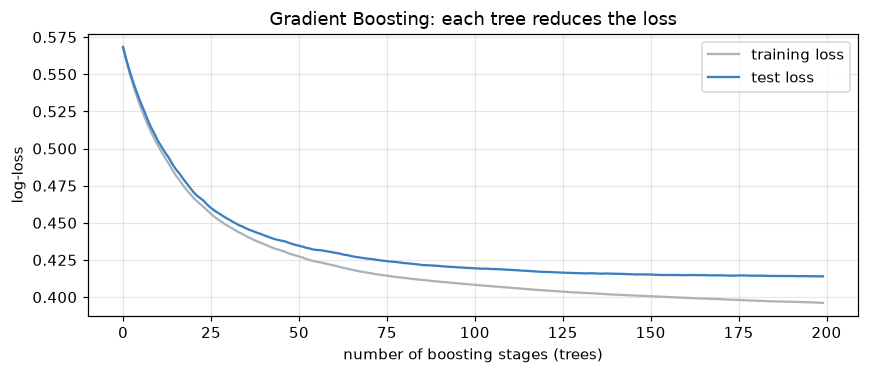

Log-loss after first tree 0.568 -> after 200 trees 0.414 (test set)


In [7]:
# Learning curve: test log-loss as trees are added (staged predictions)
gbm = gb.named_steps['gb']
Xtr_e, Xte_e = gb.named_steps['prep'].transform(X_train), gb.named_steps['prep'].transform(X_test)
def logloss(y, p): p = np.clip(p, 1e-12, 1 - 1e-12); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
tr_curve = [logloss(y_train.values, p[:, 1]) for p in gbm.staged_predict_proba(Xtr_e)]
te_curve = [logloss(y_test.values, p[:, 1]) for p in gbm.staged_predict_proba(Xte_e)]

plt.figure(figsize=(8, 3.5))
plt.plot(tr_curve, color=GREY, label='training loss'); plt.plot(te_curve, color=BLUE, label='test loss')
plt.xlabel('number of boosting stages (trees)'); plt.ylabel('log-loss')
plt.title('Gradient Boosting: each tree reduces the loss'); plt.legend(); plt.tight_layout(); plt.show()
print(f"Log-loss after first tree {te_curve[0]:.3f} -> after {len(te_curve)} trees {te_curve[-1]:.3f} (test set)")

## 4. Identify customers with a high probability of churn

In [8]:
oof = cross_val_predict(gb, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
BEST_T = float(thr[np.argmax(f1s)])
print(f"Threshold that maximises F1 on out-of-fold training predictions: {BEST_T:.3f}")

p_test = gb.predict_proba(X_test)[:, 1]
tiers = pd.cut(p_test, bins=[0, 0.3, 0.6, 1.0], labels=['Low', 'Medium', 'High'], include_lowest=True)
tier_tbl = pd.DataFrame({'tier': tiers, 'churned': y_test.values}).groupby('tier', observed=False).agg(
    customers=('churned', 'size'), actual_churn_rate=('churned', 'mean'))
tier_tbl['share_of_all_churners'] = pd.DataFrame({'tier': tiers, 'c': y_test.values}).groupby(
    'tier', observed=False)['c'].sum() / y_test.sum()
print("\nRisk tiers on the test set:")
tier_tbl

Threshold that maximises F1 on out-of-fold training predictions: 0.324

Risk tiers on the test set:


,customers,actual_churn_rate,share_of_all_churners
tier,,,
Low,875,0.103,0.241
Medium,351,0.425,0.398
High,183,0.738,0.361


In [9]:
risk = X_test.assign(customerID=id_test.values, churn_probability=p_test, actually_churned=y_test.values)
risk['risk_tier'] = tiers
high_risk = risk.sort_values('churn_probability', ascending=False)
cols = ['customerID', 'churn_probability', 'risk_tier', 'tenure', 'Contract', 'InternetService',
        'PaymentMethod', 'MonthlyCharges', 'num_addon_services', 'TechSupport', 'actually_churned']
print(f"Customers flagged High risk (p >= 0.6): {(tiers == 'High').sum()} of {len(tiers)}")
print("Top 15 customers most likely to churn:")
high_risk[cols].head(15).reset_index(drop=True)

Customers flagged High risk (p >= 0.6): 183 of 1409
Top 15 customers most likely to churn:


,customerID,churn_probability,risk_tier,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,num_addon_services,TechSupport,actually_churned
0,5178-LMXOP,0.928,High,1,Month-to-month,Fiber optic,Electronic check,95.10,2,0,1
1,0295-PPHDO,0.911,High,1,Month-to-month,Fiber optic,Electronic check,95.45,2,0,1
2,1069-XAIEM,0.904,High,1,Month-to-month,Fiber optic,Electronic check,85.05,1,0,1
3,6230-BSUXY,0.890,High,1,Month-to-month,Fiber optic,Electronic check,85.00,2,0,1
4,7181-BQYBV,0.885,High,1,Month-to-month,Fiber optic,Electronic check,102.45,4,0,1
5,9248-OJYKK,0.879,High,1,Month-to-month,Fiber optic,Electronic check,76.45,0,0,1
6,0970-ETWGE,0.873,High,1,Month-to-month,Fiber optic,Electronic check,89.55,2,0,1
7,5167-ZFFMM,0.868,High,1,Month-to-month,Fiber optic,Credit card (automatic),90.85,2,0,1
8,3722-WPXTK,0.866,High,1,Month-to-month,Fiber optic,Electronic check,88.35,2,0,1
9,6861-XWTWQ,0.857,High,7,Month-to-month,Fiber optic,Electronic check,99.25,3,0,1


Profile of High-risk vs Low-risk customers (test set):


,customers,avg_tenure_months,avg_monthly_charges,pct_month_to_month,pct_fiber,pct_electronic_check,pct_tech_support
risk_tier,,,,,,,
Low,875,42.3,57.5,28.0,24.7,17.3,36.2
Medium,351,19.8,72.5,98.3,66.7,49.6,19.4
High,183,5.6,79.5,100.0,89.1,81.4,5.5


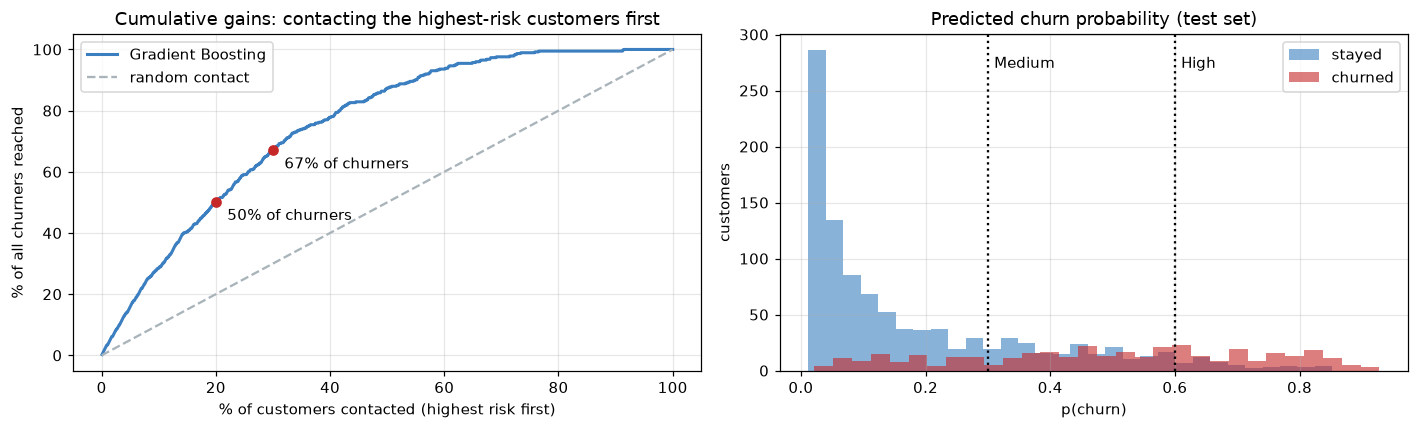

Contacting the top 20% highest-risk customers reaches 50.3% of all churners (2.5x better than random).


In [10]:
print("Profile of High-risk vs Low-risk customers (test set):")
prof = risk.groupby('risk_tier', observed=False).agg(
    customers=('tenure', 'size'), avg_tenure_months=('tenure', 'mean'), avg_monthly_charges=('MonthlyCharges', 'mean'),
    pct_month_to_month=('Contract', lambda s: (s == 'Month-to-month').mean() * 100),
    pct_fiber=('InternetService', lambda s: (s == 'Fiber optic').mean() * 100),
    pct_electronic_check=('PaymentMethod', lambda s: (s == 'Electronic check').mean() * 100),
    pct_tech_support=('TechSupport', lambda s: s.mean() * 100))
display(prof.round(1))

# lift / cumulative gains
order = np.argsort(-p_test)
gains = np.cumsum(y_test.values[order]) / y_test.sum()
frac = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(frac * 100, gains * 100, color=BLUE, lw=2, label='Gradient Boosting')
ax[0].plot([0, 100], [0, 100], color=GREY, ls='--', label='random contact')
for f in (0.2, 0.3):
    g = gains[int(f * len(order)) - 1] * 100
    ax[0].scatter(f * 100, g, color=RED, zorder=3); ax[0].annotate(f"{g:.0f}% of churners", (f * 100 + 2, g - 6))
ax[0].set(title='Cumulative gains: contacting the highest-risk customers first',
          xlabel='% of customers contacted (highest risk first)', ylabel='% of all churners reached'); ax[0].legend()
ax[1].hist(p_test[y_test.values == 0], bins=30, alpha=0.6, color=BLUE, label='stayed')
ax[1].hist(p_test[y_test.values == 1], bins=30, alpha=0.6, color=RED, label='churned')
for t, lab in ((0.3, 'Medium'), (0.6, 'High')): ax[1].axvline(t, color='k', ls=':'); ax[1].text(t + 0.01, ax[1].get_ylim()[1] * 0.9, lab)
ax[1].set(title='Predicted churn probability (test set)', xlabel='p(churn)', ylabel='customers'); ax[1].legend()
plt.tight_layout(); plt.show()
TOP20 = gains[int(0.2 * len(order)) - 1]
print(f"Contacting the top 20% highest-risk customers reaches {TOP20:.1%} of all churners "
      f"({TOP20 / 0.2:.1f}x better than random).")

## 5. Evaluation: accuracy, precision, recall, F1-score and feature importance

In [11]:
def scores(name, y_true, prob, t=0.5):
    pred = (prob >= t).astype(int)
    return {'Model': name, 'Threshold': t, 'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1-score': f1_score(y_true, pred), 'ROC-AUC': roc_auc_score(y_true, prob)}

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
logreg = Pipeline([('prep', ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
                                               ('sc', StandardScaler(), NUMERIC)])),
                   ('lr', LogisticRegression(max_iter=2000))]).fit(X_train, y_train)

eval_tbl = pd.DataFrame([
    scores('Baseline: always "no churn"', y_test, dummy.predict_proba(X_test)[:, 1]),
    scores('Logistic Regression', y_test, logreg.predict_proba(X_test)[:, 1]),
    scores('Gradient Boosting (default)', y_test, gb_default.predict_proba(X_test)[:, 1]),
    scores('Gradient Boosting (tuned)', y_test, p_test),
    scores('Gradient Boosting (tuned, F1 threshold)', y_test, p_test, BEST_T),
]).set_index('Model')
eval_tbl.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
"Baseline: always ""no churn""",0.500,0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.500,0.799,0.653,0.519,0.578,0.843
Gradient Boosting (default),0.500,0.804,0.675,0.505,0.578,0.844
Gradient Boosting (tuned),0.500,0.801,0.662,0.508,0.575,0.847
"Gradient Boosting (tuned, F1 threshold)",0.324,0.772,0.552,0.749,0.636,0.847


Gradient Boosting (tuned), threshold = 0.324

              precision    recall  f1-score   support

      Stayed      0.896     0.781     0.834      1035
     Churned      0.552     0.749     0.636       374

    accuracy                          0.772      1409
   macro avg      0.724     0.765     0.735      1409
weighted avg      0.805     0.772     0.782      1409



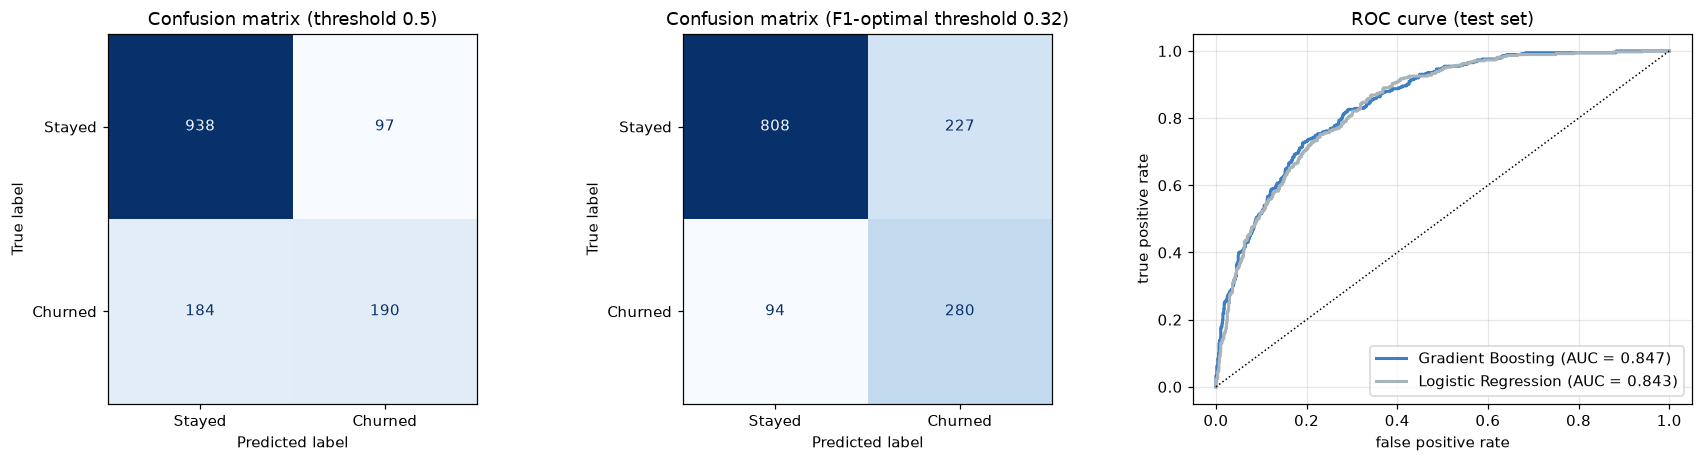

In [12]:
pred_final = (p_test >= BEST_T).astype(int)
print(f"Gradient Boosting (tuned), threshold = {BEST_T:.3f}\n")
print(classification_report(y_test, pred_final, target_names=['Stayed', 'Churned'], digits=3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, t, title in ((ax[0], 0.5, 'threshold 0.5'), (ax[1], BEST_T, f'F1-optimal threshold {BEST_T:.2f}')):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= t).astype(int)),
                           display_labels=['Stayed', 'Churned']).plot(ax=a, cmap='Blues', colorbar=False, values_format='d')
    a.set_title(f'Confusion matrix ({title})'); a.grid(False)
for name, prob, col in (('Gradient Boosting', p_test, BLUE),
                        ('Logistic Regression', logreg.predict_proba(X_test)[:, 1], GREY)):
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[2].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
ax[2].plot([0, 1], [0, 1], 'k:', lw=1)
ax[2].set(title='ROC curve (test set)', xlabel='false positive rate', ylabel='true positive rate'); ax[2].legend(loc='lower right')
plt.tight_layout(); plt.show()

### 5.1 Feature importance

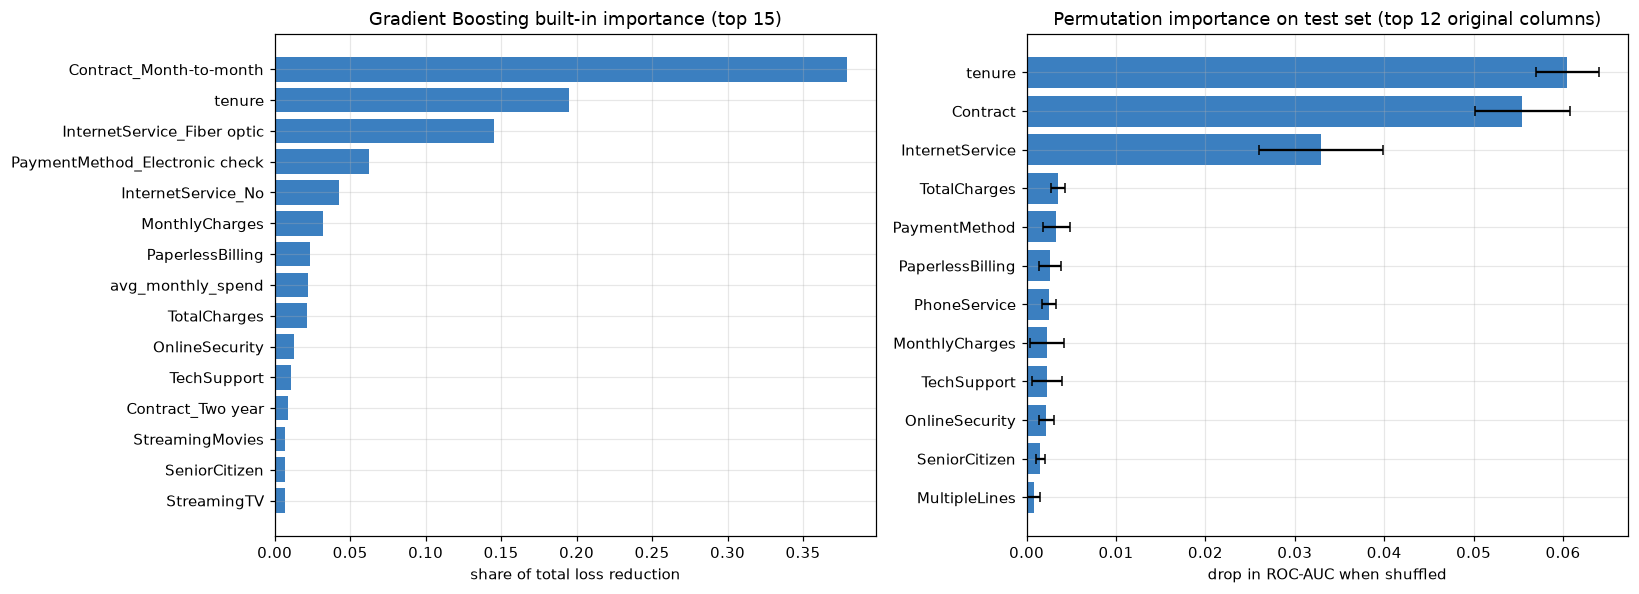

Top 5 features (built-in):      Contract_Month-to-month (0.379), tenure (0.195), InternetService_Fiber optic (0.145), PaymentMethod_Electronic check (0.062), InternetService_No (0.042)
Top 5 columns (permutation):    tenure (0.060), Contract (0.055), InternetService (0.033), TotalCharges (0.004), PaymentMethod (0.003)


In [13]:
imp = pd.Series(gbm.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
perm = permutation_importance(gb, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)
perm_s = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                      index=X_test.columns).sort_values('mean', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
top = imp.head(15)[::-1]
ax[0].barh(top.index, top.values, color=BLUE)
ax[0].set(title='Gradient Boosting built-in importance (top 15)', xlabel='share of total loss reduction')
topp = perm_s.head(12)[::-1]
ax[1].barh(topp.index, topp['mean'], xerr=topp['std'], color=BLUE, ecolor='k', capsize=3)
ax[1].set(title='Permutation importance on test set (top 12 original columns)', xlabel='drop in ROC-AUC when shuffled')
plt.tight_layout(); plt.show()

print("Top 5 features (built-in):     ", ", ".join(f"{k} ({v:.3f})" for k, v in imp.head(5).items()))
print("Top 5 columns (permutation):   ", ", ".join(f"{k} ({v:.3f})" for k, v in perm_s['mean'].head(5).items()))

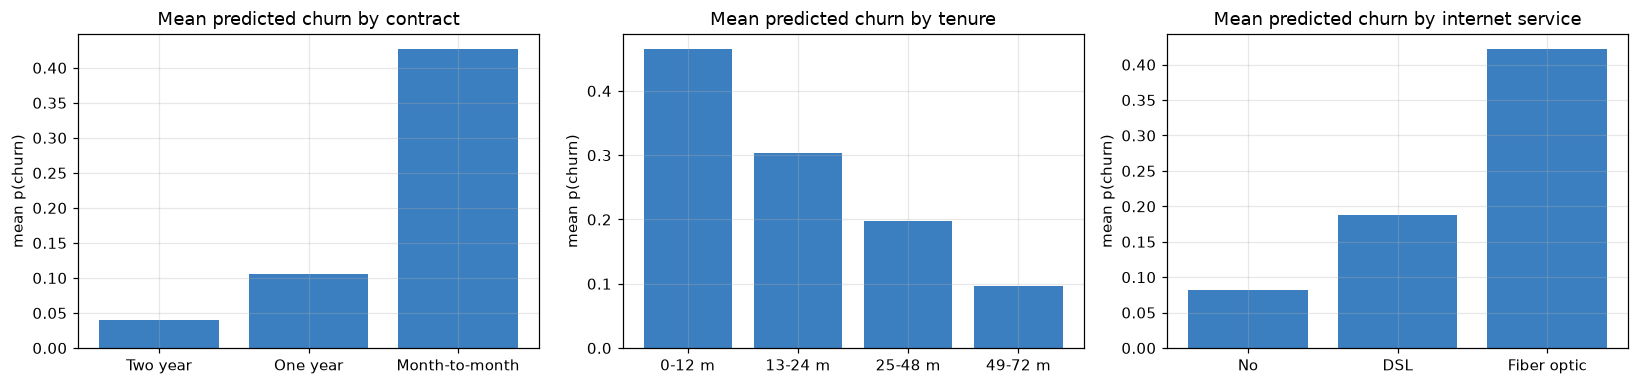

In [14]:
# Direction of the effect: churn rate across the most important drivers
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
d = X_test.assign(p=p_test)
g = d.groupby('Contract')['p'].mean().sort_values(); ax[0].bar(g.index, g.values, color=BLUE)
ax[0].set(title='Mean predicted churn by contract', ylabel='mean p(churn)')
g = d.groupby('tenure_group')['p'].mean(); ax[1].bar(g.index, g.values, color=BLUE)
ax[1].set(title='Mean predicted churn by tenure', ylabel='mean p(churn)')
g = d.groupby('InternetService')['p'].mean().sort_values(); ax[2].bar(g.index, g.values, color=BLUE)
ax[2].set(title='Mean predicted churn by internet service', ylabel='mean p(churn)')
plt.tight_layout(); plt.show()

## 6. Summary of results

In [15]:
final = eval_tbl.loc['Gradient Boosting (tuned, F1 threshold)']
base = eval_tbl.loc['Gradient Boosting (tuned)']
summary = pd.DataFrame([
    ['1', 'Load dataset', f"{len(df)} customers, {df.shape[1]} columns, churn rate {(df['Churn'] == 'Yes').mean():.1%}"],
    ['2', 'Preprocessing & encoding', f"TotalCharges fixed, 3 engineered features, {len(FEATURE_NAMES)} encoded features, stratified 80/20 split"],
    ['3', 'Gradient Boosting', f"Tuned with 5-fold CV (ROC-AUC {search.best_score_:.3f}); test ROC-AUC {base['ROC-AUC']:.3f}"],
    ['4', 'High-risk customers', f"{(tiers == 'High').sum()} flagged High risk; top 20% by risk reach {TOP20:.0%} of churners"],
    ['5', 'Evaluation (threshold 0.5)', f"Accuracy {base['Accuracy']:.3f}, Precision {base['Precision']:.3f}, Recall {base['Recall']:.3f}, F1 {base['F1-score']:.3f}"],
    ['5', f'Evaluation (threshold {BEST_T:.2f})', f"Accuracy {final['Accuracy']:.3f}, Precision {final['Precision']:.3f}, Recall {final['Recall']:.3f}, F1 {final['F1-score']:.3f}"],
    ['5', 'Feature importance', "Top drivers: " + ", ".join(perm_s.index[:4])],
], columns=['Task', 'Step', 'Result'])
with pd.option_context('display.max_colwidth', None):
    display(summary.set_index('Task'))

,Step,Result
Task,,
1,Load dataset,"7043 customers, 21 columns, churn rate 26.5%"
2,Preprocessing & encoding,"TotalCharges fixed, 3 engineered features, 32 encoded features, stratified 80/20 split"
3,Gradient Boosting,Tuned with 5-fold CV (ROC-AUC 0.849); test ROC-AUC 0.847
4,High-risk customers,183 flagged High risk; top 20% by risk reach 50% of churners
5,Evaluation (threshold 0.5),"Accuracy 0.801, Precision 0.662, Recall 0.508, F1 0.575"
5,Evaluation (threshold 0.32),"Accuracy 0.772, Precision 0.552, Recall 0.749, F1 0.636"
5,Feature importance,"Top drivers: tenure, Contract, InternetService, TotalCharges"
